In [ ]:
from google.colab import userdata
import os, json    #"Importing tools to connect Colab with my Google account and read my Kaggle login details

#  Writing Secret key from json
os.makedirs("/root/.kaggle", exist_ok=True)

token = {
    "username": userdata.get("KAGGLE_USERNAME"),
    "key": userdata.get("KAGGLE_KEY"),
}

with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(token, f)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

#  Downloading only if the data is not already there
if os.path.exists("/content/data/archive/train"):
    print("Data already exists, skipping download")
else:
    !kaggle datasets download -d uashutoshk/nepali-currency-dataset -p /content/data --unzip

#  Check
!ls /content/data/archive

Dataset URL: https://www.kaggle.com/datasets/uashutoshk/nepali-currency-dataset
License(s): unknown
100% 6.36G/6.36G [00:56<00:00, 121MB/s] 

train  validate


In [ ]:
import os, zipfile
import torch
from torch import nn
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, TensorDataset, Dataset, ConcatDataset
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image, ImageOps
from IPython.display import display, Audio

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/currency_project_cache"
os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving to:", SAVE_DIR)

cuda
Mounted at /content/drive
Saving to: /content/drive/MyDrive/currency_project_cache


In [ ]:
raw_transform = transforms.Compose([
    transforms.Resize((224, 224)),          # ResNet18  need 224* 224 pixels
    transforms.ToTensor(),
])

train_data = datasets.ImageFolder(root="/content/data/archive/train", transform=raw_transform)
test_data  = datasets.ImageFolder(root="/content/data/archive/validate", transform=raw_transform)

class_names = train_data.classes
print(class_names)
print(len(train_data), len(test_data))

['10', '100', '1000', '20', '5', '50', '500']
18819 3814


In [ ]:
#Caching the images as numbers once, so don’t have to reopen and resize them every epoch, saves time

def cache(dataset):
    loader = DataLoader(dataset, batch_size=64, num_workers=0)
    Xs, ys = [], []
    for X, y in tqdm(loader):
        Xs.append((X * 255).round().to(torch.uint8))
        ys.append(y.clone())
    return TensorDataset(torch.cat(Xs), torch.cat(ys))

train_path = f"{SAVE_DIR}/train_cache.pt"
test_path  = f"{SAVE_DIR}/test_cache.pt"

if os.path.exists(train_path) and os.path.exists(test_path):
    print("Loading cached Kaggle tensors from Drive")
    train_cached = TensorDataset(*torch.load(train_path))
    test_cached  = TensorDataset(*torch.load(test_path))
else:
    print("No cache found, caching now ")
    train_cached = cache(train_data)
    test_cached  = cache(test_data)
    torch.save(train_cached.tensors, train_path)
    torch.save(test_cached.tensors,  test_path)

print(len(train_cached), len(test_cached))

Loading cached Kaggle tensors from Drive (fast)
18819 3814


In [ ]:
def exif_loader(path):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img)
    return img.convert("RGB")

my_cache_path = f"{SAVE_DIR}/my_photos_cache.pt"

if os.path.exists(my_cache_path):
    print("Loading your photo cache from Drive (fast)")
    my_X, my_y = torch.load(my_cache_path)
else:
    print("No cache found, caching own  photos now")
    my_data = datasets.ImageFolder(root=my_root, transform=raw_transform, loader=exif_loader)
    assert my_data.classes == class_names, f"Folder names {my_data.classes} do not match {class_names}"
    print(len(my_data), "own photos")
    my_cached = cache(my_data)
    my_X, my_y = my_cached.tensors
    torch.save((my_X, my_y), my_cache_path)

HOLD_OUT = 4
gen = torch.Generator().manual_seed(42)
train_idx, test_idx = [], []
for c in range(len(class_names)):
    idx = (my_y == c).nonzero(as_tuple=True)[0]
    idx = idx[torch.randperm(len(idx), generator=gen)]
    test_idx  += idx[:HOLD_OUT].tolist()
    train_idx += idx[HOLD_OUT:].tolist()

my_train = TensorDataset(my_X[train_idx], my_y[train_idx])
my_test  = TensorDataset(my_X[test_idx],  my_y[test_idx])
print("Own photos for training:", len(my_train), "| held-out real test:", len(my_test))

No cache found, caching your photos now
237 own photos


  0%|          | 0/4 [00:00<?, ?it/s]

Own photos for training: 209 | held-out real test: 28


In [ ]:
REPEAT = 15   # my own photos are duplicated in training for 15 times

normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])

#    Augmentation, messy real-world effects, used for TRAINING only
augment = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.4, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomRotation(25),
    transforms.RandomPerspective(distortion_scale=0.3, p=0.5),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.03),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3),
])

class AugDataset(Dataset):
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        x, y = self.base[i]
        x = x.float() / 255          # back to 0-1
        x = augment(x)               # random messiness
        return normalize(x), y       # normalize LAST

class CleanDataset(Dataset):         #  in test data no augmentation
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        x, y = self.base[i]
        return normalize(x.float() / 255), y

#  mixing Kaggle train  data   and my  own photos repeated REPEAT times
mixed_train = ConcatDataset([train_cached] + [my_train] * REPEAT)
print("Kaggle train:", len(train_cached),
      "| own photos x", REPEAT, "=", len(my_train) * REPEAT,
      "| total:", len(mixed_train))

train_loader     = DataLoader(AugDataset(mixed_train), batch_size=32, shuffle=True, num_workers=2)
test_loader      = DataLoader(CleanDataset(test_cached), batch_size=32, shuffle=False)
real_test_loader = DataLoader(CleanDataset(my_test), batch_size=16, shuffle=False)

Kaggle train: 18819 | own photos x 15 = 3135 | total: 21954


In [ ]:
resnet = models.resnet18(weights="IMAGENET1K_V1")      #Loading the ResNet18
resnet.fc = nn.Linear(resnet.fc.in_features, len(class_names))

# Starting from  the  best earlier model if the file is still in Colab
for path in ["currency_resnet18_layer4.pth", "currency_resnet18_aug.pth"]:
    if os.path.exists(path):
        ckpt = torch.load(path, map_location=device)
        resnet.load_state_dict(ckpt["model"])
        print("Loaded:", path)
        break
else:
    print("No earlier checkpoint found, starting from ImageNet weights")

resnet = resnet.to(device)

# 1. Freeze everything
for param in resnet.parameters():
    param.requires_grad = False

# 2. Unfreeze ONLY layer4 and the final layer
for param in resnet.layer4.parameters():
    param.requires_grad = True
for param in resnet.fc.parameters():
    param.requires_grad = True

# 3. Two learning rates: gentle for layer4, normal for fc
optimizer = torch.optim.Adam([
    {"params": resnet.layer4.parameters(), "lr": 1e-4},
    {"params": resnet.fc.parameters(),     "lr": 1e-3},
])

loss_fn = nn.CrossEntropyLoss()    # multiclass so crossentropyloss()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 134MB/s]


No earlier checkpoint found, starting from ImageNet weights


In [ ]:
def accuracy_fn(y_true, y_pred):
    correct = (y_true == y_pred).sum().item()
    return (correct / len(y_pred)) * 100


def train_step(model, data_loader, loss_fn, optimizer, accuracy_fn, device):
    train_loss, train_acc = 0, 0
    model.train()

    # keep frozen BatchNorm layers still
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()

    for X, y in data_loader:
        X, y = X.to(device), y.to(device)

        y_logits = model(X)
        loss = loss_fn(y_logits, y)
        train_loss += loss.item()
        y_pred = y_logits.argmax(dim=1)
        train_acc += accuracy_fn(y, y_pred)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(data_loader)
    train_acc  /= len(data_loader)
    print(f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.2f}%")
    return train_loss, train_acc


def test_step(model, data_loader, loss_fn, accuracy_fn, device):
    test_loss, test_acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            y_logits = model(X)
            test_loss += loss_fn(y_logits, y).item()
            test_acc  += accuracy_fn(y, y_logits.argmax(dim=1))

    test_loss /= len(data_loader)
    test_acc  /= len(data_loader)
    print(f"Test loss: {test_loss:.4f} | Test acc: {test_acc:.2f}%\n")
    return test_loss, test_acc

In [ ]:
print("BEFORE training with own  photos ")
_ = test_step(resnet, real_test_loader, loss_fn, accuracy_fn, device)

BEFORE training with your photos (held-out real photos):
Test loss: 2.0288 | Test acc: 9.38%



In [ ]:
epochs = 8
for epoch in tqdm(range(epochs)):
    print(f"Epoch {epoch + 1}/{epochs}")
    train_step(resnet, train_loader, loss_fn, optimizer, accuracy_fn, device)
    print("Kaggle test:")
    test_step(resnet, test_loader, loss_fn, accuracy_fn, device)
    print("Held-out REAL phone photos:")
    test_step(resnet, real_test_loader, loss_fn, accuracy_fn, device)

  0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/8
Train loss: 0.2186 | Train acc: 92.35%
Kaggle test:
Test loss: 0.0444 | Test acc: 98.36%

Held-out REAL phone photos:
Test loss: 0.1438 | Test acc: 91.67%

Epoch 2/8
Train loss: 0.0589 | Train acc: 98.01%
Kaggle test:
Test loss: 0.0716 | Test acc: 97.63%

Held-out REAL phone photos:
Test loss: 0.0361 | Test acc: 96.88%

Epoch 3/8
Train loss: 0.0385 | Train acc: 98.75%
Kaggle test:
Test loss: 0.0975 | Test acc: 97.71%

Held-out REAL phone photos:
Test loss: 0.1032 | Test acc: 95.83%

Epoch 4/8
Train loss: 0.0317 | Train acc: 98.97%
Kaggle test:
Test loss: 0.0564 | Test acc: 98.33%

Held-out REAL phone photos:
Test loss: 0.1305 | Test acc: 96.88%

Epoch 5/8
Train loss: 0.0306 | Train acc: 99.01%
Kaggle test:
Test loss: 0.0509 | Test acc: 98.72%

Held-out REAL phone photos:
Test loss: 0.0525 | Test acc: 95.83%

Epoch 6/8
Train loss: 0.0283 | Train acc: 99.10%
Kaggle test:
Test loss: 0.1180 | Test acc: 97.58%

Held-out REAL phone photos:
Test loss: 0.1117 | Test acc: 95.83%

Epoc

In [ ]:
from google.colab import files

torch.save({"model": resnet.state_dict(), "classes": class_names}, "currency_resnet18_real.pth")
files.download("currency_resnet18_real.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

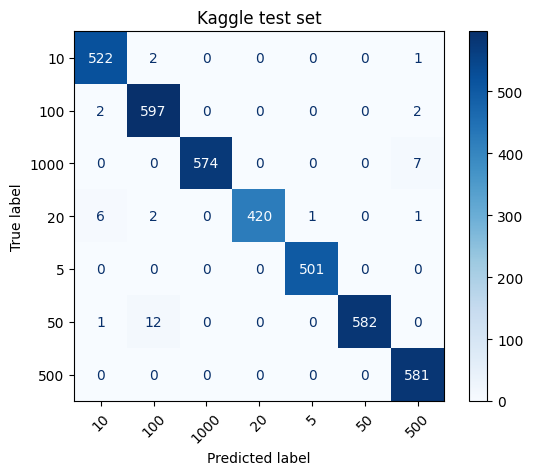

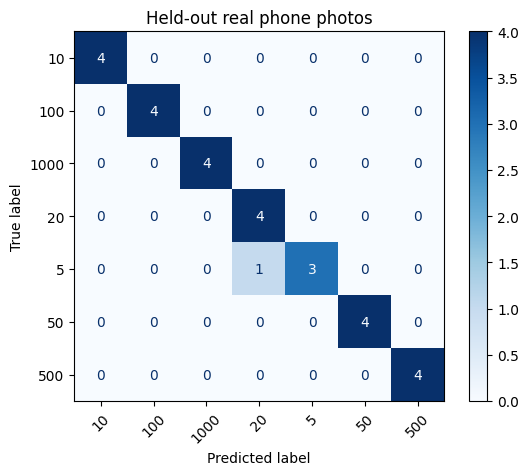

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def show_confusion(loader, title):
    resnet.eval()
    all_preds, all_labels = [], []
    with torch.inference_mode():
        for X, y in loader:
            preds = resnet(X.to(device)).argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.numpy())
    cm = confusion_matrix(all_labels, all_preds, labels=list(range(len(class_names))))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap="Blues", xticks_rotation=45)
    plt.title(title)
    plt.show()

show_confusion(test_loader, "Kaggle test set")
show_confusion(real_test_loader, "Held-out real phone photos")